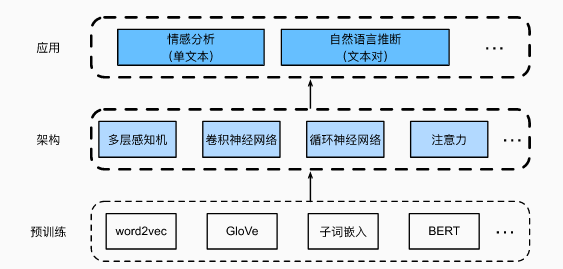

imdb数据集下载地址: http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz

In [1]:
import os
import torch
from torch import nn
import dltools

In [2]:
def read_imdb(data_dir, is_train):
    data, labels = [], []
    for label in ('pos', 'neg'):
        folder_name = os.path.join(data_dir, 'train' if is_train else 'test', label)
        for file in os.listdir(folder_name):
            with open(os.path.join(folder_name, file), 'rb') as f:
                review = f.read().decode('utf-8').replace('\n', '')
                data.append(review)
                labels.append(1 if label == 'pos' else 0)
    return data, labels

In [3]:
data_dir = r'D:\AIoT-深度学习视频版\深度学习基础\自然语言处理\NLP入门\data\aclImdb'
train_data = read_imdb(data_dir, is_train=True)
print('训练集数目: ', len(train_data[0]))

训练集数目:  25000


In [5]:
for x, y in zip(train_data[0][:3], train_data[1][:3]):
    print('标签: ', y,'review: ', x[0:60])

标签:  1 review:  Bromwell High is a cartoon comedy. It ran at the same time a
标签:  1 review:  Homelessness (or Houselessness as George Carlin stated) has 
标签:  1 review:  Brilliant over-acting by Lesley Ann Warren. Best dramatic ho


In [6]:
# 分词
train_tokens = dltools.tokenize(train_data[0], token='word')

In [7]:
train_tokens

[['Bromwell',
  'High',
  'is',
  'a',
  'cartoon',
  'comedy.',
  'It',
  'ran',
  'at',
  'the',
  'same',
  'time',
  'as',
  'some',
  'other',
  'programs',
  'about',
  'school',
  'life,',
  'such',
  'as',
  '"Teachers".',
  'My',
  '35',
  'years',
  'in',
  'the',
  'teaching',
  'profession',
  'lead',
  'me',
  'to',
  'believe',
  'that',
  'Bromwell',
  "High's",
  'satire',
  'is',
  'much',
  'closer',
  'to',
  'reality',
  'than',
  'is',
  '"Teachers".',
  'The',
  'scramble',
  'to',
  'survive',
  'financially,',
  'the',
  'insightful',
  'students',
  'who',
  'can',
  'see',
  'right',
  'through',
  'their',
  'pathetic',
  "teachers'",
  'pomp,',
  'the',
  'pettiness',
  'of',
  'the',
  'whole',
  'situation,',
  'all',
  'remind',
  'me',
  'of',
  'the',
  'schools',
  'I',
  'knew',
  'and',
  'their',
  'students.',
  'When',
  'I',
  'saw',
  'the',
  'episode',
  'in',
  'which',
  'a',
  'student',
  'repeatedly',
  'tried',
  'to',
  'burn',
  'down'

In [11]:
vocab = dltools.Vocab(train_tokens, min_freq=5, reserved_tokens=['<pad>'])

In [12]:
len(vocab)

49347

(array([ 553., 2373., 6820., 4834., 2817., 1848., 1380., 1005.,  759.,
         581.,  437.,  349.,  257.,  207.,  174.,  133.,  116.,   85.,
          75.]),
 array([  0,  50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600,
        650, 700, 750, 800, 850, 900, 950]),
 <BarContainer object of 19 artists>)

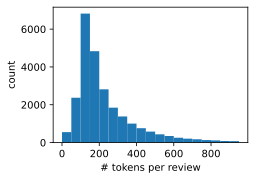

In [13]:
dltools.set_figsize()
dltools.plt.xlabel('# tokens per review')
dltools.plt.ylabel('count')
dltools.plt.hist([len(line) for line in train_tokens], bins=range(0, 1000, 50))

In [15]:
num_steps = 500 # 序列长度
train_features = torch.tensor([dltools.truncate_pad(vocab[line], num_steps, vocab['<pad>']) for line in train_tokens])

In [16]:
train_features.shape

torch.Size([25000, 500])

In [18]:
train_iter = dltools.load_array((train_features, torch.tensor(train_data[1])), 64, )

In [19]:
for X, y in train_iter:
    print('X:', X.shape, ', y:', y.shape)
    break
print('小批次数量: ', len(train_iter))

X: torch.Size([64, 500]) , y: torch.Size([64])
小批次数量:  391


In [20]:
def load_data_imdb(data_dir, batch_size, num_steps=500):
    train_data = read_imdb(data_dir, True)
    test_data = read_imdb(data_dir, False)
    train_tokens = dltools.tokenize(train_data[0], token='word')
    test_tokens = dltools.tokenize(test_data[0], token='word')
    
    vocab = dltools.Vocab(train_tokens, min_freq=5, reserved_tokens=['<pad>'])
    train_features = torch.tensor([dltools.truncate_pad(vocab[line], num_steps, vocab['<pad>']) for line in train_tokens])
    test_features = torch.tensor([dltools.truncate_pad(vocab[line], num_steps, vocab['<pad>']) for line in test_tokens])
    
    train_iter = dltools.load_array((train_features, torch.tensor(train_data[1])), 64)
    test_iter = dltools.load_array((test_features, torch.tensor(train_data[1])), 64)
    return train_iter, test_iter, vocab

In [22]:
data_dir = r'D:\AIoT-深度学习视频版\深度学习基础\自然语言处理\NLP入门\data\aclImdb'
train_iter, test_iter, vocab = load_data_imdb(data_dir, 64, num_steps=500)

In [23]:
len(train_iter)

391

In [24]:
len(test_iter)

391

In [28]:
for X, y in test_iter:
    print('X:', X.shape, ', y:', y.shape)
    print(X)
    print(y)
    break
print('小批次数量: ', len(train_iter))

X: torch.Size([64, 500]) , y: torch.Size([64])
tensor([[   9,   96,  122,  ...,    1,    1,    1],
        [4787,    0,  474,  ...,    1,    1,    1],
        [   9,  320,   42,  ...,    1,    1,    1],
        ...,
        [ 397,  219,    9,  ...,    1,    1,    1],
        [3891,  350,  455,  ...,    1,    1,    1],
        [   9,  208,  347,  ...,    1,    1,    1]])
tensor([0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1,
        1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0,
        0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0])
小批次数量:  391


In [42]:
class BiRNN(nn.Module):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers, **kwargs):
        super().__init__(**kwargs)
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.encoder = nn.LSTM(embed_size, num_hiddens, num_layers=num_layers, bidirectional=True)
        self.decoder = nn.Linear(4 * num_hiddens, 2)
        
        
    def forward(self, inputs):
        # inputs (batch_size, num_steps)
        # 循环神经网络输入的第一个维度是时间维
        # 所以要对inputs做一个转置, 转置之后的形状(num_steps, batch_size)
        # 再经过embedding层, 就变成(num_steps, batch_size, embed_size)
        embedding = self.embedding(inputs.T)
        # 为了提供内存利用率和效率, 调用flatten_parameters让parameters的数据存放在内存中连续的块中. contiguous
        self.encoder.flatten_parameters()
        # 返回两个东西: 输出, 上一个隐藏层在不同时间步的隐状态
        # outputs :(num_steps, batch_size, 2 * num_hiddens)
        outputs, _ = self.encoder(embedding)
        # 连接初始和最终时间步的隐藏状态, 做为全连接的输入.
        # (batch, 4 * num_hiddens)
        encoding = torch.cat((outputs[0], outputs[-1]), dim=1)
        outs = self.decoder(encoding)
        return outs

In [43]:
class TokenEmbedding:
    def __init__(self, file_path):
        self.idx_to_token, self.idx_to_vec = self._load_embedding(file_path)
        self.unknown_idx = 0
        self.token_to_idx = {token: idx for idx, token in enumerate(self.idx_to_token)}
    
    # 加载预训练词向量
    def _load_embedding(self, file_path):
        # bos eos unk...
        idx_to_token, idx_to_vec = ['<unk>'], []
        with open(file_path, 'r', encoding='utf-8') as f:
            for line in f:
                elems = line.rstrip().split(' ')
                token, elems = elems[0], [float(elem) for elem in elems[1:]]
                # 跳过fasttext的第一行
                if len(elems)> 1:
                    idx_to_token.append(token)
                    idx_to_vec.append(elems)
                    
        idx_to_vec = [[0] * len(idx_to_vec[0])] + idx_to_vec
        return idx_to_token, torch.tensor(idx_to_vec)
    
    def __getitem__(self, tokens):
        indices = [self.token_to_idx.get(token, self.unknown_idx) for token in tokens]
        vecs = self.idx_to_vec[torch.tensor(indices)]
        return vecs
    
    def __len__(self):
        return len(self.idx_to_token)

In [44]:
embed_size, num_hiddens, num_layers = 100, 100, 2
devices = dltools.try_all_gpus()
net = BiRNN(len(vocab), embed_size, num_hiddens, num_layers)

In [45]:
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.xavier_uniform_(m.weight)
    if type(m) == nn.LSTM:
        for param in m._flat_weights_names:
            if 'weight' in param:
                nn.init.xavier_uniform_(m._parameters[param])
                
net.apply(init_weights)

BiRNN(
  (embedding): Embedding(49347, 100)
  (encoder): LSTM(100, 100, num_layers=2, bidirectional=True)
  (decoder): Linear(in_features=400, out_features=2, bias=True)
)

In [46]:
# glove词向量
glove_embedding = TokenEmbedding(r'D:\AIoT-深度学习视频版\深度学习基础\自然语言处理\NLP入门\data\glove.6B\glove.6B.100d.txt')

In [37]:
vocab.idx_to_token

['<unk>',
 '<pad>',
 'the',
 'a',
 'and',
 'of',
 'to',
 'is',
 'in',
 'I',
 'that',
 'this',
 'it',
 '/><br',
 'was',
 'as',
 'with',
 'for',
 'but',
 'The',
 'on',
 'movie',
 'are',
 'his',
 'film',
 'have',
 'not',
 'be',
 'you',
 'he',
 'by',
 'at',
 'one',
 'an',
 'from',
 'who',
 'like',
 'all',
 'they',
 'has',
 'so',
 'just',
 'about',
 'or',
 'her',
 'out',
 'some',
 'very',
 'more',
 'This',
 'would',
 'what',
 'when',
 'good',
 'only',
 'their',
 'It',
 'if',
 'had',
 'really',
 "it's",
 'which',
 'up',
 'even',
 'can',
 'were',
 'my',
 'see',
 'no',
 'she',
 'than',
 '-',
 'been',
 'there',
 'into',
 'get',
 'will',
 'story',
 'much',
 'because',
 'other',
 'most',
 'we',
 'time',
 'me',
 'make',
 'could',
 'also',
 'do',
 'how',
 'first',
 'people',
 'its',
 '/>The',
 'any',
 'great',
 "don't",
 'made',
 'think',
 'bad',
 'him',
 'being',
 'many',
 'never',
 'then',
 'But',
 'two',
 '<br',
 'too',
 'little',
 'after',
 'where',
 'way',
 'And',
 'it.',
 'them',
 'well',
 'y

In [47]:
embeds = glove_embedding[vocab.idx_to_token]

In [39]:
embeds.shape

torch.Size([49347, 100])

In [48]:
net.embedding.weight.data.copy_(embeds)
net.embedding.weight.requires_grad = False

loss 0.168, train acc 0.933, test acc 0.798
996.3 examples/sec on [device(type='cuda', index=0)]


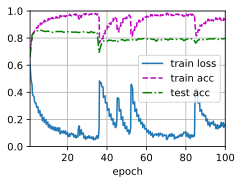

In [49]:
# 训练和评估
lr, num_epochs = 0.01, 100
trainer = torch.optim.Adam(net.parameters(), lr=lr)
loss = nn.CrossEntropyLoss(reduction='none')
dltools.train_ch13(net, train_iter, test_iter, loss, trainer, num_epochs, devices)

In [50]:
# 预测
def predict_sentiment(net, vocab, sequence):
    sequence = torch.tensor(vocab[sequence.split()], device=dltools.try_gpu())
    label = torch.argmax(net(sequence.reshape(1, -1)), dim=1)
    return 'positive' if label == 1 else 'negative'

In [51]:
predict_sentiment(net, vocab, 'this moive is great')

'positive'

In [52]:
predict_sentiment(net, vocab, 'this moive is so bad')

'negative'